threads: 6
GPU: NVIDIA GeForce RTX 3070 Ti (7.7 GB)


/tmp/ipykernel_2995795/3076987502.py:32: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  return pickle.load(f, encoding='latin1')


train: (50000, 3, 32, 32)   test: (10000, 3, 32, 32)


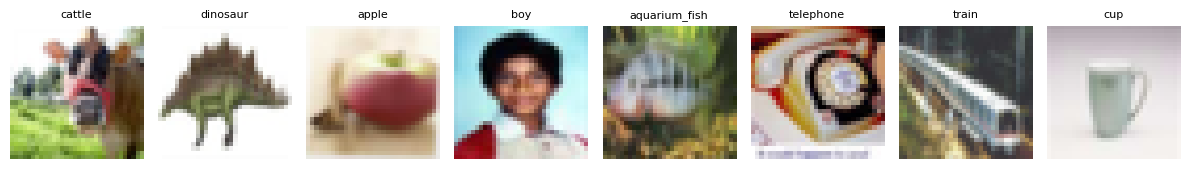

In [1]:
#N1: imports + threads + load CIFAR-100 (pickled files: meta, train, test), kept in colour

import os
N_THREADS = 6                                    # Baby-U: 12 cores, the GPU does the training (6 leaves room for a 2nd notebook)
os.environ["OMP_NUM_THREADS"] = str(N_THREADS)   # must be set BEFORE importing torch/numpy
os.environ["MKL_NUM_THREADS"] = str(N_THREADS)

import pickle, time, math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(N_THREADS)                 # PyTorch uses only these cores
print("threads:", torch.get_num_threads())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0), f"({torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB)")
    torch.backends.cuda.matmul.allow_tf32 = True     # RTX 30xx: faster float32 matrix products, same results to ~3 digits
    torch.backends.cudnn.allow_tf32 = True
else:
    print("no GPU found: running on the CPU (much slower)")

CPU_SLOT = 1     # only used on the 64-core Fatbaby: 0 -> cores 0-15, 1 -> 16-31, ... (Baby-U skips this)
if (os.cpu_count() or 0) >= 64:
    os.sched_setaffinity(0, range(16 * CPU_SLOT, 16 * CPU_SLOT + 16))
    print(f"pinned to cores {16 * CPU_SLOT}-{16 * CPU_SLOT + 15}")

BASE = '/home/worker/Scaricati/cifar'   # CHANGE to the folder on Baby-U that holds meta, train, test

def unpickle(path):
    with open(path, 'rb') as f:
        return pickle.load(f, encoding='latin1')

meta  = unpickle(os.path.join(BASE, 'meta'))
train = unpickle(os.path.join(BASE, 'train'))
test  = unpickle(os.path.join(BASE, 'test'))
fine_names = meta['fine_label_names']            # 100 names, index = fine label

# each row = 1024 red + 1024 green + 1024 blue values -> keep colour: [N, 3, 32, 32] (no grayscale, no resizing)
x_train_all = np.asarray(train['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)
y_train_all = np.array(train['fine_labels'])
x_test_all  = np.asarray(test['data'], dtype=np.uint8).reshape(-1, 3, 32, 32)
y_test_all  = np.array(test['fine_labels'])
print(f"train: {x_train_all.shape}   test: {x_test_all.shape}")

fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
for k in range(8):
    axes[k].imshow(x_train_all[k].transpose(1, 2, 0))
    axes[k].set_title(fine_names[y_train_all[k]], fontsize=8)
    axes[k].axis('off')
plt.tight_layout(); plt.show()

In [2]:
import sys, os, subprocess, torch
print("python used by this notebook:", sys.executable)
print("torch version:", torch.__version__, "| built for CUDA:", torch.version.cuda)
print("cuda available:", torch.cuda.is_available())
print("CUDA_VISIBLE_DEVICES =", os.environ.get("CUDA_VISIBLE_DEVICES"))
try:
    print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
except FileNotFoundError:
    print("nvidia-smi not found -> NVIDIA driver not installed (or not on PATH)")

python used by this notebook: /opt/miniconda3/bin/python
torch version: 2.8.0+cu128 | built for CUDA: 12.8
cuda available: True
CUDA_VISIBLE_DEVICES = None
Mon Nov 16 23:57:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 615.71.10              KMD Version: 615.71.10     CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3070 Ti     On  |   00000000:65:00.0 Off |                  N/A |
|  0%   34C    P5             27W /  290W |       4MiB /   8192MiB |      0%

In [3]:
#N2: defining 20 problems: the 20 CIFAR-100 superclasses, 5 fine classes each (same as the other notebooks)
#    the router experiment uses P6-P20; P1-P5 are listed here as before but not used

SCRIPT_NAMES = ["P1_aquatic", "P2_fish", "P3_flowers", "P4_containers", "P5_produce",
                "P6_devices", "P7_furniture", "P8_insects", "P9_carnivores", "P10_outdoor_things",
                "P11_outdoor_scenes", "P12_omni_herbivores", "P13_medium_mammals", "P14_invertebrates", "P15_people",
                "P16_reptiles", "P17_small_mammals", "P18_trees", "P19_vehicles_1", "P20_vehicles_2"]

GROUP_CLASS_NAMES = [
    ["beaver", "dolphin", "otter", "seal", "whale"],                     # P1
    ["aquarium_fish", "flatfish", "ray", "shark", "trout"],              # P2
    ["orchid", "poppy", "rose", "sunflower", "tulip"],                   # P3
    ["bottle", "bowl", "can", "cup", "plate"],                           # P4
    ["apple", "mushroom", "orange", "pear", "sweet_pepper"],             # P5
    ["clock", "keyboard", "lamp", "telephone", "television"],            # P6
    ["bed", "chair", "couch", "table", "wardrobe"],                      # P7
    ["bee", "beetle", "butterfly", "caterpillar", "cockroach"],          # P8
    ["bear", "leopard", "lion", "tiger", "wolf"],                        # P9
    ["bridge", "castle", "house", "road", "skyscraper"],                 # P10
    ["cloud", "forest", "mountain", "plain", "sea"],                     # P11
    ["camel", "cattle", "chimpanzee", "elephant", "kangaroo"],           # P12
    ["fox", "porcupine", "possum", "raccoon", "skunk"],                  # P13
    ["crab", "lobster", "snail", "spider", "worm"],                      # P14
    ["baby", "boy", "girl", "man", "woman"],                             # P15
    ["crocodile", "dinosaur", "lizard", "snake", "turtle"],              # P16
    ["hamster", "mouse", "rabbit", "shrew", "squirrel"],                 # P17
    ["maple_tree", "oak_tree", "palm_tree", "pine_tree", "willow_tree"], # P18
    ["bicycle", "bus", "motorcycle", "pickup_truck", "train"],           # P19
    ["lawn_mower", "rocket", "streetcar", "tank", "tractor"],            # P20
]

name_to_fine = {n: i for i, n in enumerate(fine_names)}
GROUP_LABELS = [[name_to_fine[n] for n in grp] for grp in GROUP_CLASS_NAMES]
for name, names, labels in zip(SCRIPT_NAMES, GROUP_CLASS_NAMES, GROUP_LABELS):
    print(f"{name:20s}", list(zip(names, labels)))
print("\n20 problems, 5 classes each, all 100 CIFAR-100 fine classes used")

P1_aquatic           [('beaver', 4), ('dolphin', 30), ('otter', 55), ('seal', 72), ('whale', 95)]
P2_fish              [('aquarium_fish', 1), ('flatfish', 32), ('ray', 67), ('shark', 73), ('trout', 91)]
P3_flowers           [('orchid', 54), ('poppy', 62), ('rose', 70), ('sunflower', 82), ('tulip', 92)]
P4_containers        [('bottle', 9), ('bowl', 10), ('can', 16), ('cup', 28), ('plate', 61)]
P5_produce           [('apple', 0), ('mushroom', 51), ('orange', 53), ('pear', 57), ('sweet_pepper', 83)]
P6_devices           [('clock', 22), ('keyboard', 39), ('lamp', 40), ('telephone', 86), ('television', 87)]
P7_furniture         [('bed', 5), ('chair', 20), ('couch', 25), ('table', 84), ('wardrobe', 94)]
P8_insects           [('bee', 6), ('beetle', 7), ('butterfly', 14), ('caterpillar', 18), ('cockroach', 24)]
P9_carnivores        [('bear', 3), ('leopard', 42), ('lion', 43), ('tiger', 88), ('wolf', 97)]
P10_outdoor_things   [('bridge', 12), ('castle', 17), ('house', 37), ('road', 68), ('skysc

In [4]:
#N3: building 20 datasets: colour 3x32x32, standardized per problem and per colour channel
#    every problem has THREE sets of images:
#      training images  2,250 (450 per class)  the network learns from these
#      validation images  250 (50 per class, taken from the 500 training images of each class)
#                             -> early stopping: when to stop a run; the network never learns from them
#      test images        500 (100 per class)  tested once per run, with its best weights (N6); never for a decision

VAL_PER_CLASS = 50

rng = np.random.default_rng(0)    # fixed: the same validation images as the TUNING = True runs of the earlier notebooks
X_tr, Y_tr, X_val, Y_val, X_te, Y_te = [], [], [], [], [], []
MEAN, STD = [], []                 # every problem's mean and std per colour channel (raw pixel values): N4 needs them
for m in range(20):
    xs_tr, ys_tr, xs_val, ys_val, xs_te, ys_te = [], [], [], [], [], []
    for new_label, old_label in enumerate(GROUP_LABELS[m]):          # labels 0-4 = position in the group list
        tr = x_train_all[y_train_all == old_label]                   # 500 training images of this class
        te = x_test_all[y_test_all == old_label]                     # 100 test images of this class
        perm = rng.permutation(len(tr))
        va, tr = tr[perm[:VAL_PER_CLASS]], tr[perm[VAL_PER_CLASS:]]   # 50 validation, 450 to learn from
        xs_tr.append(tr); ys_tr.append(np.full(len(tr), new_label))
        xs_val.append(va); ys_val.append(np.full(len(va), new_label))
        xs_te.append(te); ys_te.append(np.full(len(te), new_label))
    x_tr = torch.tensor(np.concatenate(xs_tr), dtype=torch.float32)  # [2250, 3, 32, 32]
    x_val = torch.tensor(np.concatenate(xs_val), dtype=torch.float32)  # [250, 3, 32, 32]
    x_te = torch.tensor(np.concatenate(xs_te), dtype=torch.float32)  # [500, 3, 32, 32]
    mean = x_tr.mean(dim=(0, 2, 3), keepdim=True)                    # one mean and std per colour channel,
    std  = x_tr.std(dim=(0, 2, 3), keepdim=True)                     # from this problem's training images only
    MEAN.append(mean.flatten()); STD.append(std.flatten())
    X_tr.append((x_tr - mean) / std); Y_tr.append(torch.tensor(np.concatenate(ys_tr), dtype=torch.long))
    X_val.append((x_val - mean) / std); Y_val.append(torch.tensor(np.concatenate(ys_val), dtype=torch.long))
    X_te.append((x_te - mean) / std); Y_te.append(torch.tensor(np.concatenate(ys_te), dtype=torch.long))
    print(f"{SCRIPT_NAMES[m]:20s} train {len(x_tr):5d}  validation {len(x_val):4d}  test {len(x_te):4d}  "
          f"channel means {[round(v, 1) for v in mean.flatten().tolist()]}")

X_tr, Y_tr   = torch.stack(X_tr), torch.stack(Y_tr)     # [20, 2250, 3, 32, 32] and [20, 2250]  (every problem has the same size)
X_val, Y_val = torch.stack(X_val), torch.stack(Y_val)   # [20, 250, 3, 32, 32]  and [20, 250]
X_te, Y_te   = torch.stack(X_te), torch.stack(Y_te)     # [20, 500, 3, 32, 32]  and [20, 500]
MEAN, STD    = torch.stack(MEAN), torch.stack(STD)     # [20, 3] and [20, 3]
print(f"\nX_tr {tuple(X_tr.shape)}   X_val {tuple(X_val.shape)} (validation)   X_te {tuple(X_te.shape)} (test)")

P1_aquatic           train  2250  validation  250  test  500  channel means [108.1, 122.2, 127.2]
P2_fish              train  2250  validation  250  test  500  channel means [106.2, 117.8, 116.6]
P3_flowers           train  2250  validation  250  test  500  channel means [133.4, 104.0, 78.0]
P4_containers        train  2250  validation  250  test  500  channel means [148.5, 139.3, 130.4]
P5_produce           train  2250  validation  250  test  500  channel means [153.0, 125.4, 91.9]
P6_devices           train  2250  validation  250  test  500  channel means [142.2, 136.9, 134.0]
P7_furniture         train  2250  validation  250  test  500  channel means [155.4, 137.4, 124.5]
P8_insects           train  2250  validation  250  test  500  channel means [141.8, 136.9, 109.6]
P9_carnivores        train  2250  validation  250  test  500  channel means [120.2, 111.9, 94.7]
P10_outdoor_things   train  2250  validation  250  test  500  channel means [123.7, 130.0, 130.4]
P11_outdoor_scenes   tr

In [5]:
#N4: settings, augmentation and the ViT (the same code as the other ViT notebooks), the 17 jobs of the router
#    experiment, and how the images reach them. ONE compound network at a = A_ROUTER, with 17 jobs:
#      P1        router 1: which GROUP of 3 superclasses the image belongs to          (5 answers: group 1-5)
#      P2        router 2: which POSITION the superclass has in its group               (3 answers: 1st, 2nd, 3rd;
#                                                                                         outputs 4 and 5 are not used)
#      P6 - P20  the 15 superclass classifiers, 5 fine classes each: the same jobs as in the other notebooks
#    P3, P4 and P5 are not used; the superclasses of P1-P5 (aquatic mammals, fish, flowers, containers, produce) neither.
#    Every job builds its weights from the 6 G sets with its own pattern, exactly as before (P1 = 111000, P2 = 110100,
#    P6 = 101010, ...). The routers choose the classifier: chosen = the superclass at (group, position) in GROUPS.

DEVICE        = 'cuda' if torch.cuda.is_available() else 'cpu'
CLASSES_PER   = 5

IMG, PATCH, CH = 32, 4, 3
N_PATCHES     = (IMG // PATCH) ** 2        # 64 patches per image (8 x 8)
PATCH_DIM     = PATCH * PATCH * CH         # 48 numbers per patch (4 x 4 x 3)
TOKENS        = N_PATCHES + 1              # 64 patches + 1 CLS token = 65
D             = 128                        # numbers per token
DEPTH         = 6                          # encoder blocks
HEADS         = 4                          # 4 heads x 32 dims
MLP_DIM       = 256                        # MLP inside each block: 128 -> 256 -> 128

BATCH_SIZE    = 32                         # per job per step -> 17 x 32 = 544 images per step
LEARNING_RATE = 1e-4                       # the same learning rate as the other ViT notebooks
A_ROUTER      = 0.0                        # a of this experiment: 0 = the original compound network (MR infinite)
WEIGHT_DECAY  = 0.05
NUM_EPOCHS    = 100                        # at most 100 epochs: early stopping can end a run sooner
PATIENCE      = 10                         # early stopping: stop when the END-TO-END validation accuracy has not
                                           # improved for 10 epochs in a row
WARMUP_EPOCHS = 5
N_RUNS        = 50                         # runs, each from new random weights (can be raised later: N6 keeps the
                                           # finished runs and adds the rest)
PRINT_EVERY_EPOCHS = 10                    # print one line every 10 epochs (the early-stopping check runs after EVERY epoch)
RESULTS_FILE  = f'router_compound_a{A_ROUTER:.1f}_lr1e-4.json'      # N6 saves every finished run here, N7 reads it
FORWARD_CHAIN_FILE = 'compound_a_chain_warmstart_lr1e-4.json'       # N7 compares with its a = 0 stage, if it is in this folder
RANDOM_START_FILE  = 'compound_a_values_lr1e-4_early_stopping.json' # (for A_ROUTER = 0.1 ... 1.0: the a-values notebook)
N_TRAIN       = X_tr.shape[1]                       # 2,250 per superclass (50 per class are held out)
STEPS_PER_EPOCH = N_TRAIN // BATCH_SIZE             # 70: one pass over each classifier's training images
TOTAL_STEPS   = NUM_EPOCHS * STEPS_PER_EPOCH
WARMUP_STEPS  = WARMUP_EPOCHS * STEPS_PER_EPOCH

X_tr, Y_tr, X_te, Y_te = X_tr.to(DEVICE), Y_tr.to(DEVICE), X_te.to(DEVICE), Y_te.to(DEVICE)   # ~0.7 GB, stays on the GPU
X_val, Y_val = X_val.to(DEVICE), Y_val.to(DEVICE)

USE_AMP = DEVICE == 'cuda'       # bfloat16 mixed precision on the GPU tensor cores (~2x faster); the weight sets stay float32

def amp():
    return torch.autocast(device_type=DEVICE, dtype=torch.bfloat16, enabled=USE_AMP)

# every weight tensor of one ViT: [out, in]  (no biases; LayerNorm has no learnable gain or bias)
SHAPES = {'patch': (D, PATCH_DIM), 'cls': (D,), 'pos': (TOKENS, D), 'head': (CLASSES_PER, D)}
for l in range(DEPTH):
    SHAPES[f'b{l}.qkv']  = (3 * D, D)       # Q, K, V together: 128 -> 384
    SHAPES[f'b{l}.proj'] = (D, D)           # joins the 4 heads: 128 -> 128
    SHAPES[f'b{l}.fc1']  = (MLP_DIM, D)     # 128 -> 256
    SHAPES[f'b{l}.fc2']  = (D, MLP_DIM)     # 256 -> 128
PARAMS_PER_VIT = sum(math.prod(s) for s in SHAPES.values())      # 801,664


def new_weight_sets(n_sets):
    """n_sets complete copies of every ViT tensor, stored as [n_sets, out, in]; small random start (std 0.02)"""
    G = {}
    for k, s in SHAPES.items():
        t = torch.empty(n_sets, *s, device=DEVICE)
        nn.init.trunc_normal_(t, std=0.02, a=-0.04, b=0.04)
        G[k] = nn.Parameter(t)
    return G


def lr_factor(step):
    """linear warmup for WARMUP_EPOCHS, then cosine decay to 0 at the last step"""
    if step < WARMUP_STEPS:
        return (step + 1) / WARMUP_STEPS
    p = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
    return 0.5 * (1 + math.cos(math.pi * p))


def augment(x):
    """training only: random crop (pad 4, crop 32x32) + random horizontal flip, a different one for every image"""
    M, Bsz = x.shape[:2]
    x = x.reshape(M * Bsz, CH, IMG, IMG)
    xp = F.pad(x, (4, 4, 4, 4)).permute(0, 2, 3, 1)                       # [N, 40, 40, 3]; padding 0 = channel mean
    N = xp.shape[0]
    ox = torch.randint(0, 9, (N,), device=x.device)
    oy = torch.randint(0, 9, (N,), device=x.device)
    ar = torch.arange(IMG, device=x.device)
    rows = (oy[:, None] + ar)[:, :, None]                                  # [N, 32, 1]
    cols = (ox[:, None] + ar)[:, None, :]                                  # [N, 1, 32]
    out = xp[torch.arange(N, device=x.device)[:, None, None], rows, cols].permute(0, 3, 1, 2)   # [N, 3, 32, 32]
    flip = torch.rand(N, device=x.device) < 0.5
    out = torch.where(flip[:, None, None, None], out.flip(3), out)
    return out.reshape(M, Bsz, CH, IMG, IMG)


def vit_forward(x, W):
    """x: [M, B, 3, 32, 32] images of M jobs; W: every tensor as [M, out, in] = one ViT per job.
       returns [M, B, 5] scores. All M jobs run at the same time, each with its own weights."""
    M, Bsz = x.shape[:2]
    p = x.unfold(3, PATCH, PATCH).unfold(4, PATCH, PATCH)                  # [M, B, 3, 8, 8, 4, 4]
    p = p.permute(0, 1, 3, 4, 2, 5, 6).reshape(M, Bsz, N_PATCHES, PATCH_DIM)   # [M, B, 64, 48]
    t = torch.einsum('mbpc,mdc->mbpd', p, W['patch'])                     # [M, B, 64, 128]
    cls = W['cls'][:, None, None, :].expand(M, Bsz, 1, D)
    t = torch.cat([cls, t], dim=2) + W['pos'][:, None]                     # [M, B, 65, 128]
    for l in range(DEPTH):
        h = F.layer_norm(t, (D,))
        qkv = torch.einsum('mbtd,med->mbte', h, W[f'b{l}.qkv'])            # [M, B, 65, 384]
        qkv = qkv.reshape(M * Bsz, TOKENS, 3, HEADS, D // HEADS).permute(2, 0, 3, 1, 4)   # 3 x [M*B, 4, 65, 32]
        att = F.scaled_dot_product_attention(qkv[0], qkv[1], qkv[2])        # softmax(Q K^T / sqrt(32)) V
        att = att.transpose(1, 2).reshape(M, Bsz, TOKENS, D)               # join the 4 heads: [M, B, 65, 128]
        t = t + torch.einsum('mbtd,med->mbte', att, W[f'b{l}.proj'])       # residual 1
        h = F.layer_norm(t, (D,))
        h = F.gelu(torch.einsum('mbtd,med->mbte', h, W[f'b{l}.fc1']))      # [M, B, 65, 256]
        t = t + torch.einsum('mbte,mde->mbtd', h, W[f'b{l}.fc2'])          # residual 2
    c = F.layer_norm(t[:, :, 0], (D,))                                     # CLS token: [M, B, 128]
    return torch.einsum('mbd,mcd->mbc', c, W['head'])                      # [M, B, 5]


def problem_losses(out, y):
    """mean cross-entropy of each job's batch: [M]"""
    return F.cross_entropy(out.reshape(-1, CLASSES_PER), y.reshape(-1), reduction='none').reshape(out.shape[0], -1).mean(1)


def mr_percent(a):
    return math.inf if a == 0 else 100 * (1 - a) / a

def mr_text(a):
    """MR as text: '0%', '11%', '25%', ..., '900%', and 'inf' for a = 0"""
    m = mr_percent(a)
    return "inf" if math.isinf(m) else f"{m:.0f}%"


# ---------------------------------------------------------------- THE 17 JOBS
SUPERCLASSES = list(range(5, 20))          # P6 ... P20 = problems 5 ... 19 of N2/N3 (counted from 0)
N_SUPER      = len(SUPERCLASSES)           # 15
GROUPS       = [SUPERCLASSES[3 * g:3 * g + 3] for g in range(5)]   # 5 groups of 3, in number order:
                                           # {P6,P7,P8} {P9,P10,P11} {P12,P13,P14} {P15,P16,P17} {P18,P19,P20}
POS_NAMES    = ['1st', '2nd', '3rd']
JOB_PATTERNS = [0, 1] + SUPERCLASSES       # the pattern of each job (row of B_PATTERN): P1, P2, then P6 ... P20
N_JOBS       = len(JOB_PATTERNS)           # 17
JOB_NAMES    = ['P1_group_router', 'P2_position_router'] + [SCRIPT_NAMES[s] for s in SUPERCLASSES]

assert sorted(s for grp in GROUPS for s in grp) == SUPERCLASSES and all(len(grp) == 3 for grp in GROUPS)
SUPER_IDX  = torch.tensor(SUPERCLASSES, device=DEVICE)       # to take the 15 superclasses out of X_tr, X_val, X_te
SUPER_ROWS = torch.arange(N_SUPER, device=DEVICE)[:, None]   # superclass number 0-14 (P6 = 0 ... P20 = 14), one per row
GROUP_OF   = torch.zeros(N_SUPER, dtype=torch.long, device=DEVICE)   # the right answer of P1 for each superclass (0-4)
POS_OF     = torch.zeros(N_SUPER, dtype=torch.long, device=DEVICE)   # the right answer of P2 (0 = 1st, 1 = 2nd, 2 = 3rd)
GROUP_POS_TO_SUPER = torch.zeros(5, 3, dtype=torch.long, device=DEVICE)   # (P1's answer, P2's answer) -> chosen classifier
for g, grp in enumerate(GROUPS):
    for p, s in enumerate(grp):
        j = SUPERCLASSES.index(s)
        GROUP_OF[j], POS_OF[j], GROUP_POS_TO_SUPER[g, p] = g, p, j
TRUE_GROUP, TRUE_POS = GROUP_OF[:, None], POS_OF[:, None]    # one per row, like SUPER_ROWS
DISPLAY_ORDER = [SUPERCLASSES.index(s) for grp in GROUPS for s in grp]   # N7 shows the superclasses group by group

MASK = torch.zeros(N_JOBS, 1, CLASSES_PER, device=DEVICE)
MASK[1, 0, 3:] = -1e9                      # P2: outputs 4 and 5 are switched off (added -1e9: they never win, and the
                                           # softmax of P2's loss runs over its first 3 outputs only)

FINE_OF = torch.tensor([GROUP_LABELS[s] for s in SUPERCLASSES], device=DEVICE)   # [15, 5]: the CIFAR-100 fine class of
                                                                                  # each answer of each classifier
assert len(set(FINE_OF.flatten().tolist())) == 5 * N_SUPER, "the 15 superclasses must have 75 different fine classes"

KEYS = ['p1', 'p2', 'route', 'given', 'e2e']                 # the five accuracies
MEASURES = {'p1':    'P1 router: group (5 groups)',
            'p2':    'P2 router: position in the group (3)',
            'route': 'routing: P1 and P2 right (1 of 15)',
            'given': 'classifier, own superclass given (1 of 5)',
            'e2e':   'END-TO-END: routers + chosen classifier (1 of 75)'}
CHANCE = {'p1': 100 / 5, 'p2': 100 / 3, 'route': 100 / 15, 'given': 100 / 5, 'e2e': 100 / 75}


# ---------------------------------------------------------------- WHAT THE ROUTERS SEE
# N3 standardized every superclass with its own mean and std (per colour channel). A router has to decide WITHOUT
# knowing the superclass, so it cannot use those numbers: the routers get ONE standardization for all 15 superclasses,
# with the mean and std of every colour channel over all their training images. The classifiers keep their own
# superclass's standardization (N3), as in the other notebooks.
m_, v_ = MEAN[SUPERCLASSES], STD[SUPERCLASSES] ** 2          # [15, 3]: every superclass's raw mean and variance
COMMON_MEAN = m_.mean(0)                                      # [3] (every superclass has the same number of images)
COMMON_STD  = (v_ + (m_ - COMMON_MEAN) ** 2).mean(0).sqrt()   # [3]  std over all 15 x 2,250 training images
R_SCALE = (STD[SUPERCLASSES] / COMMON_STD).to(DEVICE)         # [15, 3]: own standardization -> common standardization
R_SHIFT = ((MEAN[SUPERCLASSES] - COMMON_MEAN) / COMMON_STD).to(DEVICE)
C_SCALE = (STD[SUPERCLASSES][None] / STD[SUPERCLASSES][:, None]).to(DEVICE)   # [15 classifiers, 15 superclasses, 3]:
C_SHIFT = ((MEAN[SUPERCLASSES][None] - MEAN[SUPERCLASSES][:, None])           # superclass s's standardization -> the
           / STD[SUPERCLASSES][:, None]).to(DEVICE)                           # standardization of classifier j (N5 test)

def to_router(x, s):
    """x: images standardized with their own superclass's numbers (N3); s: their superclass (0-14), one per image.
       returns the same images with the common standardization of the routers: (raw - COMMON_MEAN) / COMMON_STD"""
    return x * R_SCALE[s][..., None, None] + R_SHIFT[s][..., None, None]


# ---------------------------------------------------------------- COMPOUND: 6 G sets, each job uses its own 3 + a x the other 3
NUM_SETS = 6

# 1 = one of the problem's OWN 3 G sets, 0 = one of the other 3: the same 20 patterns as in all the other notebooks
B_PATTERN = torch.tensor([
    [1,1,1,0,0,0],   # P1   -> router 1 (group)
    [1,1,0,1,0,0],   # P2   -> router 2 (position)
    [1,1,0,0,1,0],   # P3   (not used)
    [1,1,0,0,0,1],   # P4   (not used)
    [1,0,1,1,0,0],   # P5   (not used)
    [1,0,1,0,1,0],   # P6
    [1,0,1,0,0,1],   # P7
    [1,0,0,1,1,0],   # P8
    [1,0,0,1,0,1],   # P9
    [1,0,0,0,1,1],   # P10
    [0,1,1,1,0,0],   # P11
    [0,1,1,0,1,0],   # P12
    [0,1,1,0,0,1],   # P13
    [0,1,0,1,1,0],   # P14
    [0,1,0,1,0,1],   # P15
    [0,1,0,0,1,1],   # P16
    [0,0,1,1,1,0],   # P17
    [0,0,1,1,0,1],   # P18
    [0,0,1,0,1,1],   # P19
    [0,0,0,1,1,1],   # P20
], dtype=torch.float32, device=DEVICE)

def set_a(value):
    """sets a: b table = 1 for the job's own 3 G sets, a for the other 3 (only the 17 used patterns);
       scale = sqrt(3 + 3a^2), so the built weights start at the same size as one normal ViT"""
    global a, B_CONFIGS, SCALE
    a = value
    B_CONFIGS = (B_PATTERN + a * (1 - B_PATTERN))[JOB_PATTERNS]   # [17, 6]
    SCALE = (3 + 3 * a ** 2) ** 0.5

def g_set_lr(lr):
    """the learning rate AdamW uses for the G sets, with the same rule as the other notebooks (a = 0: 5.77e-5)"""
    return lr * SCALE / (3 + 3 * a)

def build_weights(G):
    """every tensor of job m's ViT:  W[m] = sum_n b[m,n] * G[n] / scale   (all 17 jobs in one einsum)"""
    return {k: torch.einsum('mn,n...->m...', B_CONFIGS, g) / SCALE for k, g in G.items()}

set_a(A_ROUTER)
LR_G = g_set_lr(LEARNING_RATE)


# ---------------------------------------------------------------- THE BATCHES
POOL = N_SUPER * N_TRAIN                   # 33,750: the training images of all 15 superclasses, for the routers

class Batches:
    """one batch of BATCH_SIZE for every job at every step:
         P1, P2   : images drawn from the POOL of all 15 superclasses, each router in its own random order;
                    labels: P1 = the group (0-4), P2 = the position in the group (0-2)
         P6 - P20 : images of their own superclass with the fine class (0-4), reshuffled after every full pass (as before)"""
    def __init__(self):
        self.pos_c = N_TRAIN
        self.pos_r = POOL
    def next(self):
        if self.pos_c + BATCH_SIZE > N_TRAIN:
            self.perm_c = torch.argsort(torch.rand(N_SUPER, N_TRAIN, device=DEVICE), dim=1)
            self.pos_c = 0
        if self.pos_r + BATCH_SIZE > POOL:
            self.perm_r = torch.argsort(torch.rand(2, POOL, device=DEVICE), dim=1)   # one order for P1, one for P2
            self.pos_r = 0
        ic = self.perm_c[:, self.pos_c:self.pos_c + BATCH_SIZE]             # [15, 32]: image numbers in each superclass
        ir = self.perm_r[:, self.pos_r:self.pos_r + BATCH_SIZE]             # [2, 32]: image numbers in the pool
        self.pos_c += BATCH_SIZE
        self.pos_r += BATCH_SIZE
        x_c = X_tr[SUPER_IDX[:, None], ic]                                   # [15, 32, 3, 32, 32]
        y_c = Y_tr[SUPER_IDX[:, None], ic]                                   # [15, 32]
        s_r, i_r = ir // N_TRAIN, ir % N_TRAIN                               # superclass (0-14) and number of each pool image
        x_r = to_router(X_tr[SUPER_IDX[s_r], i_r], s_r)                      # [2, 32, 3, 32, 32], common standardization
        y_r = torch.stack([GROUP_OF[s_r[0]], POS_OF[s_r[1]]])               # P1: its group;  P2: its position in the group
        return torch.cat([x_r, x_c]), torch.cat([y_r, y_c])                  # [17, 32, 3, 32, 32], [17, 32]


# ---------------------------------------------------------------- WHAT IS SET UP
print(f"Device: {DEVICE}   mixed precision (bfloat16): {USE_AMP}")
print(f"ViT: {N_PATCHES} patches + CLS = {TOKENS} tokens of {D}, {DEPTH} blocks, {HEADS} heads, MLP {MLP_DIM} "
      f"-> {PARAMS_PER_VIT:,} weights per ViT")
print(f"Compound network at a = {a:.1f} (MR {mr_text(a)}): {NUM_SETS} G sets x {PARAMS_PER_VIT:,} = "
      f"{NUM_SETS * PARAMS_PER_VIT:,} parameters, {N_JOBS} jobs   scale {SCALE:.3f}   learning rate {LEARNING_RATE:.0e} "
      f"-> G-set lr {LR_G:.2e}")
print(f"\n{'job':20s} {'pattern':>7}   {'learns from':38s} answers")
for m, p in enumerate(JOB_PATTERNS):
    pattern = ''.join(str(int(v)) for v in B_PATTERN[p].tolist())
    if m == 0:
        src, ans = f"all 15 superclasses ({POOL:,} images)", "group 1-5"
    elif m == 1:
        src, ans = f"all 15 superclasses ({POOL:,} images)", "1st / 2nd / 3rd in the group (outputs 4, 5 not used)"
    else:
        src, ans = f"its own superclass ({N_TRAIN:,} images)", ", ".join(GROUP_CLASS_NAMES[p])
    print(f"{JOB_NAMES[m]:20s} {pattern:>7}   {src:38s} {ans}")
print("\nthe groups (P1's answer) and the positions in them (P2's answer):")
for g, grp in enumerate(GROUPS):
    print(f"  group {g + 1}: " + ",  ".join(f"{POS_NAMES[i]} {SCRIPT_NAMES[s]}" for i, s in enumerate(grp)))
print(f"  routing: the classifier at (P1's group, P2's position) answers; e.g. group 2, 2nd -> {SCRIPT_NAMES[GROUPS[1][1]]}")
uses = B_PATTERN[JOB_PATTERNS].sum(0).int().tolist()
print("jobs that use each G set: " + ",  ".join(f"G{n + 1}: {u}" for n, u in enumerate(uses)))
print(f"chance: " + ",  ".join(f"{k} {CHANCE[k]:.1f}%" for k in KEYS))
print(f"routers' common standardization (raw pixel values): mean {[round(v, 1) for v in COMMON_MEAN.tolist()]}  "
      f"std {[round(v, 1) for v in COMMON_STD.tolist()]}")
print(f"\nEpochs: at most {NUM_EPOCHS}, early stopping on the end-to-end validation accuracy with patience {PATIENCE}   "
      f"Steps/epoch: {STEPS_PER_EPOCH} (each router sees {STEPS_PER_EPOCH * BATCH_SIZE:,} of the {POOL:,} pool images per epoch)"
      f"   Warmup epochs: {WARMUP_EPOCHS}   {N_RUNS} runs")


Device: cuda   mixed precision (bfloat16): True
ViT: 64 patches + CLS = 65 tokens of 128, 6 blocks, 4 heads, MLP 256 -> 801,664 weights per ViT
Compound network at a = 0.0 (MR inf): 6 G sets x 801,664 = 4,809,984 parameters, 17 jobs   scale 1.732   learning rate 1e-04 -> G-set lr 5.77e-05

job                  pattern   learns from                            answers
P1_group_router       111000   all 15 superclasses (33,750 images)    group 1-5
P2_position_router    110100   all 15 superclasses (33,750 images)    1st / 2nd / 3rd in the group (outputs 4, 5 not used)
P6_devices            101010   its own superclass (2,250 images)      clock, keyboard, lamp, telephone, television
P7_furniture          101001   its own superclass (2,250 images)      bed, chair, couch, table, wardrobe
P8_insects            100110   its own superclass (2,250 images)      bee, beetle, butterfly, caterpillar, cockroach
P9_carnivores         100101   its own superclass (2,250 images)      bear, leopard, lion, 

In [6]:
#N5: THE FIVE ACCURACIES AND ONE TRAINING RUN WITH EARLY STOPPING (N6 uses it for every run)
# every step: 32 images for each of the 17 jobs (Batches, N4)
#     P1, P2   : 32 images from all 15 superclasses together, labels = the group / the position in the group
#     P6 - P20 : 32 images of their own superclass, label = the fine class, as in the other notebooks
#   -> every job's ViT (built from its 3 G sets) -> 17 losses added -> one backward pass -> one AdamW step on the 6 G sets
# after every epoch: the five accuracies on the validation images (250 per superclass, 3,750 in all)
#   early stopping on the END-TO-END accuracy:
#   better than ever before -> save a copy of the weights, counter back to 0;   not better -> counter + 1; at PATIENCE: stop
# at the end: back to the best weights, then the test images ONCE, through the whole system (test_routed)
#
# END-TO-END: an image is right only if P1 AND P2 choose its own classifier AND that classifier gives the right class.
#   A wrong route can never give the right class: every classifier only knows its own 5 fine classes, and the 15
#   superclasses have 75 different fine classes. So   end-to-end right = routing right AND own classifier right.
#   Validation uses this (it is cheap); on the test images the whole system really runs and the two are compared.

HEADER = (f"{'a':>4} {'MR':>5} {'Run':>4} {'Ep':>4} | {'Tr loss':>8} | {'Tr P1':>6} {'Tr P2':>6} {'Tr cls':>6} | "
          f"{'Val P1':>6} {'Val P2':>6} {'route':>6} {'given':>6} {'e2e':>6}")


@torch.no_grad()
def router_answers(W, X, chunk=100):
    """P1's and P2's answers for every image of the 15 superclasses in X (X_val or X_te)
       returns group [15, n] (0-4) and position [15, n] (0-2); row = the image's true superclass"""
    Wr = {k: w[:2] for k, w in W.items()}                                  # the weights of P1 and P2
    n = X.shape[1]
    group, pos = [], []
    for i in range(0, n, chunk):
        x = to_router(X[SUPER_IDX, i:i + chunk], SUPER_ROWS)               # [15, c, 3, 32, 32], common standardization
        c = x.shape[1]
        x = x.reshape(1, N_SUPER * c, CH, IMG, IMG).expand(2, -1, -1, -1, -1)   # the same images for P1 and P2
        with amp():
            out = vit_forward(x, Wr)                                       # [2, 15c, 5]
        ans = (out.float() + MASK[:2]).argmax(-1).reshape(2, N_SUPER, c)   # P2 can only answer 0, 1, 2
        group.append(ans[0])
        pos.append(ans[1])
    return torch.cat(group, 1), torch.cat(pos, 1)


@torch.no_grad()
def classifier_answers(W, X, chunk=100):
    """the answer (0-4) of every superclass's own classifier for the images of its superclass: [15, n]"""
    Wc = {k: w[2:] for k, w in W.items()}                                  # the weights of P6 ... P20
    n = X.shape[1]
    ans = []
    for i in range(0, n, chunk):
        with amp():
            out = vit_forward(X[SUPER_IDX, i:i + chunk], Wc)               # [15, c, 5]
        ans.append(out.argmax(-1))
    return torch.cat(ans, 1)


def measures(group, pos, given_ok):
    """the five accuracies (%), overall and for every superclass, from P1's answers, P2's answers and whether each
       image's own classifier was right (all [15, n]; row = true superclass)"""
    g_ok = group == TRUE_GROUP
    p_ok = pos == TRUE_POS
    route_ok = g_ok & p_ok                                                 # the right classifier is chosen
    e2e_ok = route_ok & given_ok                                           # ... and it gives the right class
    per = {k: (ok.float().mean(1) * 100).tolist() for k, ok in zip(KEYS, [g_ok, p_ok, route_ok, given_ok, e2e_ok])}
    overall = {k: float(np.mean(v)) for k, v in per.items()}               # every superclass has the same number of images
    return overall, per


@torch.no_grad()
def evaluate(G, X, Y):
    """the five accuracies on X, Y (N5 uses X_val, Y_val after every epoch): P1 and P2 answer every image, each classifier
       answers the images of its own superclass; end-to-end = routing right AND own classifier right"""
    W = build_weights(G)
    group, pos = router_answers(W, X)
    given_ok = classifier_answers(W, X) == Y[SUPER_IDX]
    return measures(group, pos, given_ok)


@torch.no_grad()
def test_routed(G, chunk=20):
    """THE WHOLE SYSTEM on the test images (500 per superclass, 7,500 in all), once per run, with the best weights:
         image -> P1 answers the group, P2 the position -> the classifier at that place in GROUPS answers (0-4)
               -> turned into its CIFAR-100 fine class -> right or wrong
       Every test image goes to ALL 15 classifiers (each with its own standardization), so the answer of the chosen
       classifier and the answer of the image's own classifier come from the same numbers. The routed end-to-end result
       is compared, image by image, with the shortcut used for validation; the number of differences is returned."""
    W = build_weights(G)
    group, pos = router_answers(W, X_te)                                   # [15, 500] each
    Wc = {k: w[2:] for k, w in W.items()}
    n = X_te.shape[1]
    answers = []
    for i in range(0, n, chunk):
        x = X_te[SUPER_IDX, i:i + chunk]                                   # [15 superclasses, c, 3, 32, 32]
        c = x.shape[1]
        x = x[None] * C_SCALE[:, :, None, :, None, None] + C_SHIFT[:, :, None, :, None, None]   # [15 classifiers, 15, c, ...]
        with amp():
            out = vit_forward(x.reshape(N_SUPER, N_SUPER * c, CH, IMG, IMG), Wc)   # every classifier, every image
        answers.append(out.argmax(-1).reshape(N_SUPER, N_SUPER, c))
    answers = torch.cat(answers, 2)                     # [classifier j, superclass s, image i]: j's answer (0-4)

    y = Y_te[SUPER_IDX]                                 # [15, 500]: the right answer inside the image's own superclass
    s_ = SUPER_ROWS.expand(-1, n)                       # the superclass of every image
    i_ = torch.arange(n, device=DEVICE).expand(N_SUPER, -1)
    chosen = GROUP_POS_TO_SUPER[group, pos]             # the classifier P1 + P2 choose (0-14)
    final = FINE_OF[chosen, answers[chosen, s_, i_]]    # the system's answer, as a CIFAR-100 fine class
    routed_ok = final == FINE_OF[s_, y]                 # END-TO-END, by really routing every image
    given_ok = answers[s_, s_, i_] == y                 # the image's own classifier
    overall, per = measures(group, pos, given_ok)
    shortcut = (group == TRUE_GROUP) & (pos == TRUE_POS) & given_ok
    table = torch.bincount((s_ * N_SUPER + chosen).flatten(), minlength=N_SUPER * N_SUPER).reshape(N_SUPER, N_SUPER)
    return {'te': overall, 'te_per': per,
            'te_e2e_routed': routed_ok.float().mean().item() * 100,
            'check_mismatches': int((routed_ok != shortcut).sum()),
            'routing_table': table.tolist()}            # [true superclass, chosen classifier]: number of test images


def train_one_run(label, show_estimate=False):
    """trains the 17 jobs of one compound network from new random weights at a = A_ROUTER, with early stopping on the
       end-to-end validation accuracy. returns (numbers of the BEST weights, the best weights);
       the best weights are then tested once on the test images, through the whole system"""
    G = new_weight_sets(NUM_SETS)
    optimizer = torch.optim.AdamW(G.values(), lr=LR_G, betas=(0.9, 0.999), weight_decay=WEIGHT_DECAY)
    batches = Batches()
    step_global = 0
    best_acc, best_epoch, waited = -1.0, 0, 0       # best end-to-end validation accuracy so far, its epoch, epochs without improvement
    history = []                                    # the five validation accuracies after every epoch

    for epoch in range(NUM_EPOCHS):
        t_ep = time.time()
        epoch_loss = 0.0
        correct = torch.zeros(N_JOBS, device=DEVICE)
        for step in range(STEPS_PER_EPOCH):
            for pg in optimizer.param_groups:
                pg['lr'] = LR_G * lr_factor(step_global)
            step_global += 1

            x, y = batches.next()                          # [17, 32, 3, 32, 32], [17, 32]
            x = augment(x)
            with amp():
                out = vit_forward(x, build_weights(G))     # [17, 32, 5]
            out = out.float() + MASK                       # P2: outputs 4 and 5 switched off
            total_loss = problem_losses(out, y).sum()      # plain sum of the 17 job losses

            optimizer.zero_grad(set_to_none=True)
            total_loss.backward()
            optimizer.step()

            epoch_loss += total_loss.item()
            correct += (out.argmax(-1) == y).sum(1)

        avg_tr = epoch_loss / STEPS_PER_EPOCH / N_JOBS
        c = (correct / (STEPS_PER_EPOCH * BATCH_SIZE) * 100).tolist()
        tr = {'p1': c[0], 'p2': c[1], 'cls': float(np.mean(c[2:]))}       # train accuracy: P1, P2, the 15 classifiers

        if show_estimate and epoch == 0:
            sec = time.time() - t_ep
            print(f"  first epoch took {sec:.0f}s -> at most about {sec * NUM_EPOCHS / 60:.0f} min per run (less when it stops early)")

        # ---- early stopping: the validation images after every epoch
        val, _ = evaluate(G, X_val, Y_val)
        history.append([round(val[k], 3) for k in KEYS])
        if val['e2e'] > best_acc:                                             # better than ever before
            best_acc, best_epoch, waited = val['e2e'], epoch + 1, 0
            best_G = {name: w.detach().clone() for name, w in G.items()}     # save a copy of the weights
            best = {'val': val, 'tr': tr, 'tr_loss': avg_tr}
        else:                                                                 # not better
            waited += 1
        stop = waited >= PATIENCE

        if (epoch + 1) % PRINT_EVERY_EPOCHS == 0 or stop:
            print(f"{label} {epoch+1:4d} | {avg_tr:8.4f} | {tr['p1']:6.2f} {tr['p2']:6.2f} {tr['cls']:6.2f} | "
                  f"{val['p1']:6.2f} {val['p2']:6.2f} {val['route']:6.2f} {val['given']:6.2f} {val['e2e']:6.2f}")
        if stop:
            print(f"  early stop after epoch {epoch+1}: no better end-to-end validation accuracy for {PATIENCE} epochs "
                  f"-> back to the weights of epoch {best_epoch}")
            break

    with torch.no_grad():                                                     # back to the best weights
        for name in G:
            G[name].copy_(best_G[name])
    best.update(best_epoch=best_epoch, stop_epoch=epoch + 1, history=history)
    best.update(test_routed(G))                                               # the test images: only here, only once
    return best, G

print("train_one_run is ready")
print(HEADER)


train_one_run is ready
   a    MR  Run   Ep |  Tr loss |  Tr P1  Tr P2 Tr cls | Val P1 Val P2  route  given    e2e


In [7]:
#N6: ALL RUNS, ONE AFTER THE OTHER: N_RUNS runs of the router experiment at a = A_ROUTER, every run from new random
#    weights, all with the same settings. Each run stops when its end-to-end validation accuracy has not improved for
#    PATIENCE epochs, goes back to its best weights and tests them ONCE on the test images, through the whole system.
#    Every finished run is saved at once in RESULTS_FILE. If the notebook stops (restart, power cut): run N1 to N5 again
#    and then this cell: it continues where it stopped; the finished runs are kept and not repeated.

import json

SETTINGS = {'a': A_ROUTER, 'learning_rate': LEARNING_RATE, 'patience': PATIENCE, 'max_epochs': NUM_EPOCHS,
            'batch_size': BATCH_SIZE, 'groups': GROUPS, 'job_patterns': JOB_PATTERNS}

def save_results():
    tmp = RESULTS_FILE + '.tmp'
    with open(tmp, 'w') as f:
        json.dump({'settings': SETTINGS, 'runs': runs}, f)
    os.replace(tmp, RESULTS_FILE)               # the old file is replaced only when the new one is complete

runs = []                                       # one dict per finished run: the numbers of its best weights
if os.path.exists(RESULTS_FILE):
    saved = json.load(open(RESULTS_FILE))
    if saved['settings'] != SETTINGS:
        raise ValueError(f"{RESULTS_FILE} was made with other settings: rename it (to keep it) or delete it, then run N6 again")
    runs = saved['runs']
    print(f"continuing from {RESULTS_FILE}: {len(runs)} finished run(s) kept")

todo = max(0, N_RUNS - len(runs))
print(f"ROUTER EXPERIMENT on CIFAR-100: one compound ViT at a = {A_ROUTER:.1f} (MR {mr_text(A_ROUTER)}) with 17 jobs "
      f"(routers P1, P2 + classifiers P6-P20), learning rate {LEARNING_RATE:.0e}, early stopping on the end-to-end "
      f"validation accuracy with patience {PATIENCE}: {N_RUNS} runs, {todo} still to do")
print("Tr = the training batches (augmented);  Val = the validation images (250 per superclass): only for early stopping;  "
      "TEST = the test images, once per run")
print("route = P1 and P2 both right;  given = the image's own classifier right;  e2e = end-to-end (route right AND own classifier right)")
print(HEADER)
print("-" * len(HEADER))
t0, done = time.time(), 0

for run in range(len(runs), N_RUNS):
    r, _ = train_one_run(f"{A_ROUTER:4.1f} {mr_text(A_ROUTER):>5} {run + 1:4d}", show_estimate=(done == 0))
    r['a'] = A_ROUTER
    runs.append(r)
    save_results()
    done += 1
    took = time.time() - t0
    te = r['te']
    print(f"  → run {run + 1}  best epoch {r['best_epoch']} (stopped after {r['stop_epoch']})  TEST: P1 {te['p1']:.2f}%  "
          f"P2 {te['p2']:.2f}%  routing {te['route']:.2f}%  given {te['given']:.2f}%  END-TO-END {te['e2e']:.2f}%  "
          f"(routed check: {r['check_mismatches']} differences)  "
          f"[{took / 3600:.2f} h, about {took / done * (todo - done) / 3600:.2f} h left]")

if runs:
    print(f"\n{len(runs)} runs saved in {RESULTS_FILE}.  Mean test accuracy:  "
          + ",  ".join(f"{k} {np.mean([r['te'][k] for r in runs]):.2f}%" for k in KEYS))


ROUTER EXPERIMENT on CIFAR-100: one compound ViT at a = 0.0 (MR inf) with 17 jobs (routers P1, P2 + classifiers P6-P20), learning rate 1e-04, early stopping on the end-to-end validation accuracy with patience 10: 50 runs, 50 still to do
Tr = the training batches (augmented);  Val = the validation images (250 per superclass): only for early stopping;  TEST = the test images, once per run
route = P1 and P2 both right;  given = the image's own classifier right;  e2e = end-to-end (route right AND own classifier right)
   a    MR  Run   Ep |  Tr loss |  Tr P1  Tr P2 Tr cls | Val P1 Val P2  route  given    e2e
-------------------------------------------------------------------------------------------
  first epoch took 2s -> at most about 4 min per run (less when it stops early)
 0.0   inf    1   10 |   1.2337 |  32.90  41.65  49.76 |  36.72  41.84  15.57  50.75   7.89
 0.0   inf    1   20 |   1.0450 |  40.80  44.42  59.68 |  41.41  46.64  19.79  57.97  11.25
 0.0   inf    1   30 |   0.9464 

ROUTER EXPERIMENT: one compound ViT at a = 0.0 (MR inf) with 17 jobs, 50 runs, learning rate 1e-04, early stopping on the end-to-end validation accuracy (patience 10)
                                                    chance |             test |   train     val
-----------------------------------------------------------------------------------------------
P1 router: group (5 groups)                          20.0% |  52.85% ±  1.20% |  52.44%  52.01%
P2 router: position in the group (3)                 33.3% |  53.59% ±  0.93% |  53.79%  54.57%
routing: P1 and P2 right (1 of 15)                    6.7% |  31.29% ±  1.21% |       -  31.38%
classifier, own superclass given (1 of 5)            20.0% |  65.63% ±  0.61% |  78.92%  64.87%
END-TO-END: routers + chosen classifier (1 of 75)     1.3% |  21.32% ±  1.00% |       -  21.20%
test:  the best weights of each run, tested once on all test images (500 per superclass); mean ± std over the runs
train: the training batches (augmented) in the

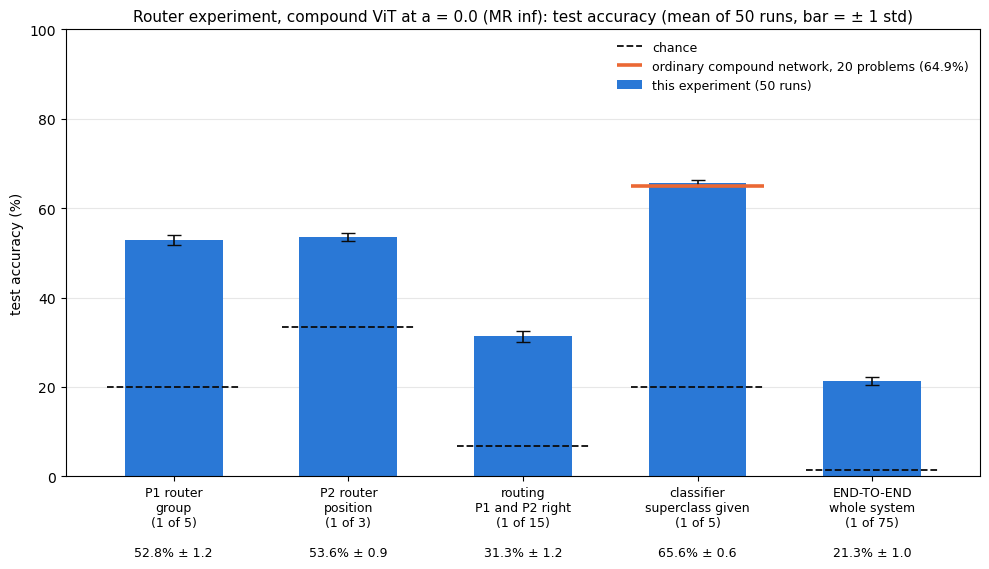

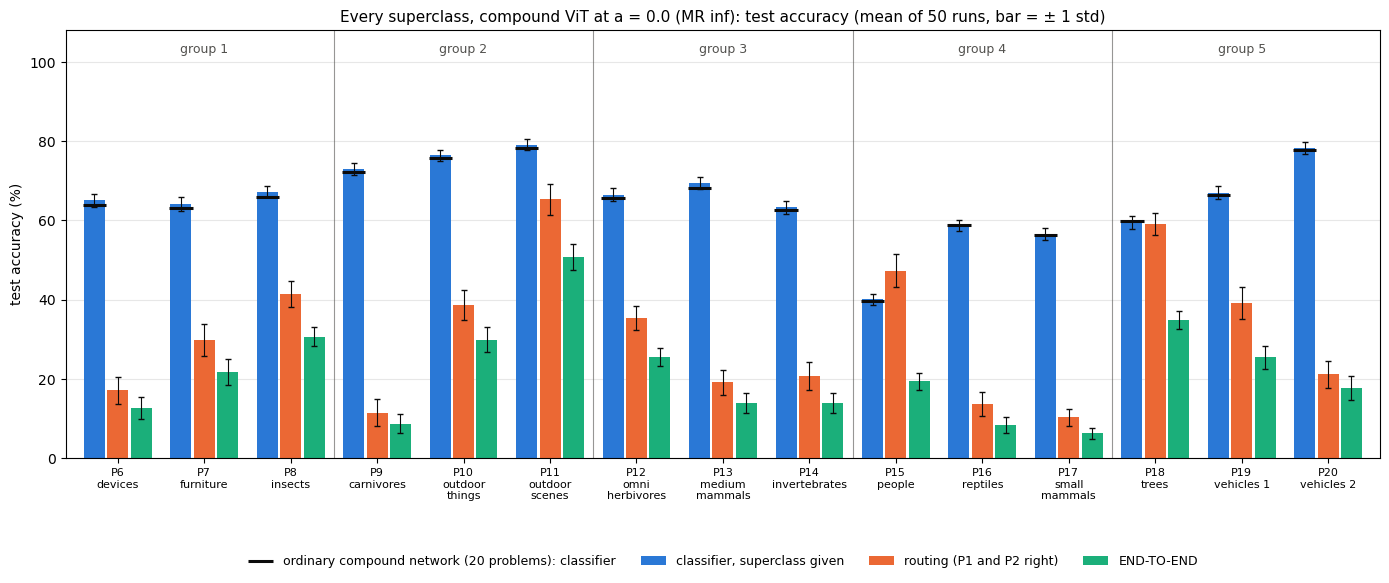

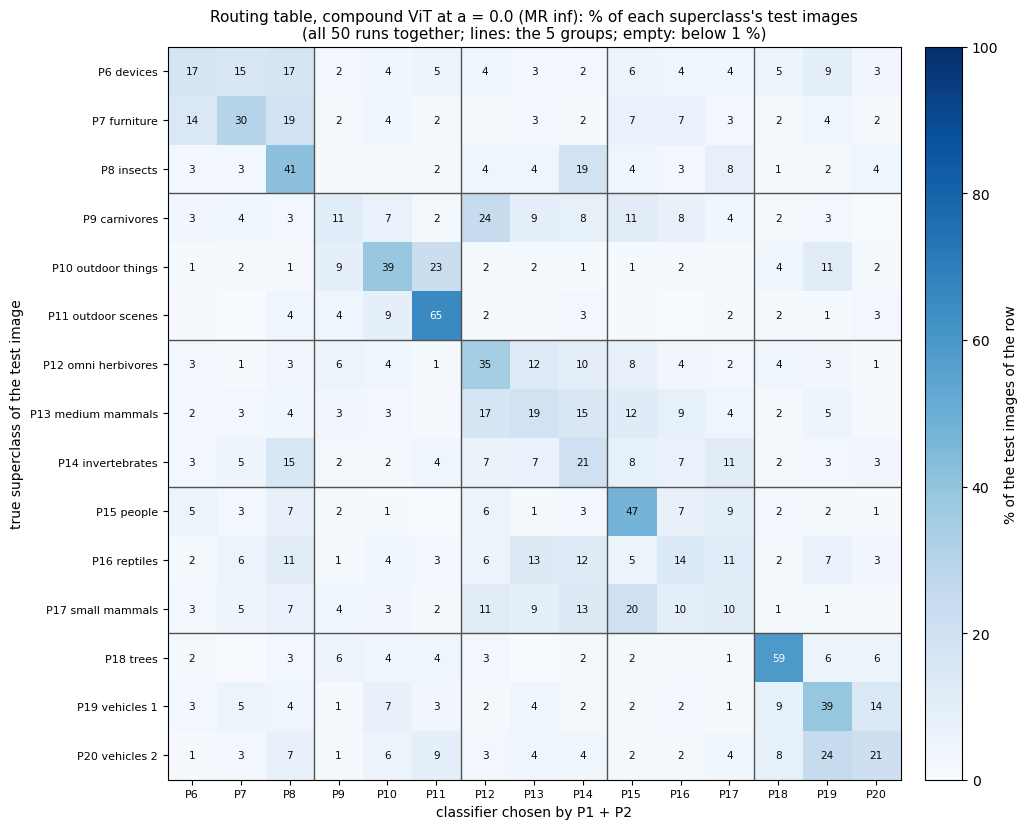

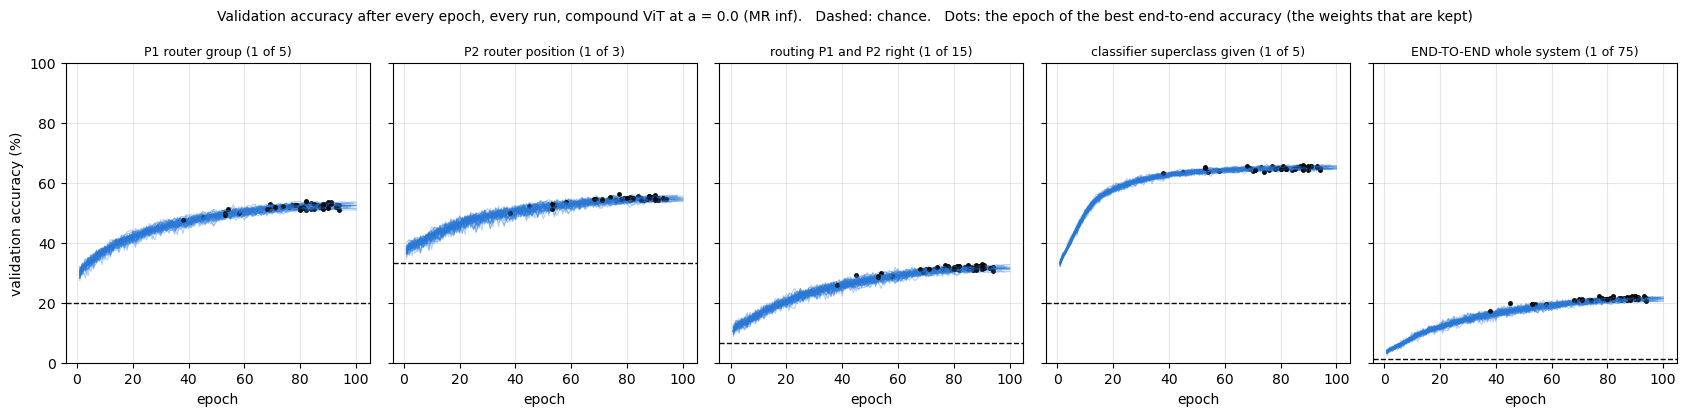

saved the plots: router_a0.0_accuracies.png, router_a0.0_superclasses.png, router_a0.0_routing_table.png, router_a0.0_validation_curves.png


In [8]:
#N7: RESULTS OF THE ROUTER EXPERIMENT (the test images, the best weights of every run; mean ± std over the runs).
#    It reads RESULTS_FILE, so it also works after a restart (run N1 to N4 first) and shows the runs finished so far.
#      P1          the group is right (5 groups)                                          chance 20 %
#      P2          the position in the group is right (1st, 2nd, 3rd)                     chance 33.3 %
#      routing     P1 AND P2 right = the right classifier is chosen (1 of 15)             chance 6.7 %
#      given       the image's own classifier is right (as if the routing were perfect)   chance 20 %
#      end-to-end  the whole system is right (1 of 75 fine classes)                       chance 1.3 %
#    Every table and plot shows a and MR = (1 - a) / a.

import json
saved = json.load(open(RESULTS_FILE))
runs = saved['runs']
assert runs, f"{RESULTS_FILE} has no finished runs yet: run N6 first"
n_runs = len(runs)
n_test = int(np.sum(runs[0]['routing_table']))                       # test images per run (500 per superclass)
title_a = f"a = {A_ROUTER:.1f} (MR {mr_text(A_ROUTER)})"
te = {k: np.array([r['te'][k] for r in runs]) for k in KEYS}         # [runs]
per = {k: np.array([r['te_per'][k] for r in runs]) for k in KEYS}    # [runs, 15]

def mean_std(x):
    return f"{np.mean(x):6.2f}% ± {np.std(x):5.2f}%"

# ---------------------------------------------------------------- 1. THE FIVE ACCURACIES
print(f"ROUTER EXPERIMENT: one compound ViT at {title_a} with 17 jobs, {n_runs} runs, learning rate "
      f"{saved['settings']['learning_rate']:.0e}, early stopping on the end-to-end validation accuracy (patience "
      f"{saved['settings']['patience']})")
header = f"{'':50s} {'chance':>7} | {'test':>16} | {'train':>7} {'val':>7}"
print(header)
print("-" * len(header))
TRAIN_OF = {'p1': 'p1', 'p2': 'p2', 'given': 'cls'}
for k in KEYS:
    tr = f"{np.mean([r['tr'][TRAIN_OF[k]] for r in runs]):6.2f}%" if k in TRAIN_OF else f"{'-':>7}"
    print(f"{MEASURES[k]:50s} {CHANCE[k]:6.1f}% | {mean_std(te[k])} | {tr} {np.mean([r['val'][k] for r in runs]):6.2f}%")
print("test:  the best weights of each run, tested once on all test images (500 per superclass); mean ± std over the runs")
print("train: the training batches (augmented) in the epoch of the best weights (P1 and P2 get different training images,")
print("       so routing and end-to-end have no train value)")
print("val:   the validation images, at the best weights")
be, se = [r['best_epoch'] for r in runs], [r['stop_epoch'] for r in runs]
print(f"best epoch {np.mean(be):.0f} ({min(be)}-{max(be)}), stopped after {np.mean(se):.0f} ({min(se)}-{max(se)}) epochs")
mis = sum(r['check_mismatches'] for r in runs)
print(f"routed check: end-to-end counted by really routing every test image to the chosen classifier, against routing "
      f"right AND own classifier right: {mis} differences in {n_runs} runs x {n_test:,} test images")


# ---------------------------------------------------------------- 2. THE CLASSIFIERS NEXT TO THE ORDINARY COMPOUND NETWORK
def reference_given():
    """test accuracy of P6-P20 in the ordinary compound network (20 problems, one classifier each, no routers) at the
       same a and with the same settings. a = 0: the a = 0 stage of the forward chain (it starts from new random
       weights); a = 0.1 ... 1.0: the a-values notebook (random start). Returns ([runs, 15] accuracies, file) or
       (None, the reason)"""
    path = FORWARD_CHAIN_FILE if A_ROUTER == 0 else RANDOM_START_FILE
    if not os.path.exists(path):
        return None, f"{path} is not in this folder"
    d = json.load(open(path))
    if (d['learning_rate'], d['patience'], d['max_epochs']) != (LEARNING_RATE, PATIENCE, NUM_EPOCHS):
        return None, f"{path} was made with other settings"
    if A_ROUTER == 0:
        accs = [ch[0]['te_accs'] for ch in d['chains'] if ch and ch[0]['a'] == 0.0]
    else:
        accs = [r['te_accs'] for r in d['runs'].get(f'{A_ROUTER:.1f}', [])]
    if not accs:
        return None, f"{path} has no runs at a = {A_ROUTER:.1f}"
    return np.array(accs)[:, SUPERCLASSES], path

ref, ref_src = reference_given()
print()
if ref is None:
    print(f"reference (the ordinary compound network, 20 problems): not shown, because {ref_src}")
else:
    print(f"reference: the ordinary compound network at {title_a}: 20 problems, one classifier each, no routers")
    print(f"           ({ref_src}: {len(ref)} runs; those runs stopped on the mean validation accuracy of their 20 problems)")
    print(f"classifier with its own superclass given, mean of P6-P20:  this experiment {np.mean(te['given']):.2f}%   "
          f"ordinary compound network {ref.mean():.2f}%   difference {np.mean(te['given']) - ref.mean():+.2f} points")


# ---------------------------------------------------------------- 3. EVERY SUPERCLASS
print(f"\ntest accuracy of every superclass (mean over the runs);  ref. = the ordinary compound network;  "
      f"diff = given - ref. (points)")
h = (f"{'superclass':20s} {'group':>5} {'pos':>4} | {'P1':>6} {'P2':>6} {'routing':>7} | {'given':>6} {'ref.':>6} "
     f"{'diff':>6} | {'e2e':>6}")
print(h)
print("-" * len(h))
for j in DISPLAY_ORDER:
    rt = (f"{ref[:, j].mean():6.1f} {per['given'][:, j].mean() - ref[:, j].mean():+6.1f}" if ref is not None
          else f"{'-':>6} {'-':>6}")
    print(f"{SCRIPT_NAMES[SUPERCLASSES[j]]:20s} {GROUP_OF[j].item() + 1:5d} {POS_NAMES[POS_OF[j].item()]:>4} | "
          f"{per['p1'][:, j].mean():6.1f} {per['p2'][:, j].mean():6.1f} {per['route'][:, j].mean():7.1f} | "
          f"{per['given'][:, j].mean():6.1f} {rt} | {per['e2e'][:, j].mean():6.1f}")


# ---------------------------------------------------------------- 4. WHERE THE TEST IMAGES GO
T = np.sum([r['routing_table'] for r in runs], axis=0).astype(float)   # [true superclass, chosen classifier], all runs
gof = GROUP_OF.tolist()
same_group = np.equal.outer(gof, gof)
right = np.trace(T) / T.sum() * 100
in_group = (T * same_group).sum() / T.sum() * 100 - right
print(f"\nwhere the test images go (all runs together):  to their own classifier {right:.2f}%   to another classifier of "
      f"the same group (P1 right, P2 wrong) {in_group:.2f}%   to a classifier of another group (P1 wrong) "
      f"{100 - right - in_group:.2f}%")
R = T / T.sum(1, keepdims=True) * 100                                  # % of each superclass's test images
print("routing table: % of the test images of each superclass (row) that go to each classifier (column)")
print(f"{'':20s} " + " ".join(f"{'P' + str(SUPERCLASSES[j] + 1):>5}" for j in DISPLAY_ORDER))
for i in DISPLAY_ORDER:
    print(f"{SCRIPT_NAMES[SUPERCLASSES[i]]:20s} " + " ".join(f"{R[i, j]:5.1f}" for j in DISPLAY_ORDER))


# ---------------------------------------------------------------- 5. THE PLOTS
BLUE, ORANGE, AQUA, INK, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e'
SHORT = {'p1': 'P1 router\ngroup\n(1 of 5)', 'p2': 'P2 router\nposition\n(1 of 3)',
         'route': 'routing\nP1 and P2 right\n(1 of 15)', 'given': 'classifier\nsuperclass given\n(1 of 5)',
         'e2e': 'END-TO-END\nwhole system\n(1 of 75)'}
tag = f"a{A_ROUTER:.1f}"
names = [SCRIPT_NAMES[SUPERCLASSES[j]].split('_', 1)[1] for j in DISPLAY_ORDER]   # 'devices', 'furniture', ...
pnums = [f"P{SUPERCLASSES[j] + 1}" for j in DISPLAY_ORDER]

# ---- plot 1: the five accuracies
fig, ax = plt.subplots(figsize=(10, 5.8))
xs = np.arange(len(KEYS))
means, stds = [te[k].mean() for k in KEYS], [te[k].std() for k in KEYS]
ax.bar(xs, means, width=0.56, color=BLUE, yerr=stds, capsize=5, error_kw=dict(ecolor=INK, lw=1.2),
       label=f'this experiment ({n_runs} runs)')
ax.hlines([CHANCE[k] for k in KEYS], xs - 0.38, xs + 0.38, colors=INK, linestyles='--', lw=1.3, label='chance')
if ref is not None:
    ax.hlines(ref.mean(), 3 - 0.38, 3 + 0.38, colors=ORANGE, lw=2.6,
              label=f'ordinary compound network, 20 problems ({ref.mean():.1f}%)')
ax.set_xticks(xs)
ax.set_xticklabels([f"{SHORT[k]}\n\n{m:.1f}% ± {s:.1f}" for k, m, s in zip(KEYS, means, stds)], fontsize=9)
ax.set_ylim(0, 100)
ax.set_ylabel('test accuracy (%)')
ax.set_title(f"Router experiment, compound ViT at {title_a}: test accuracy (mean of {n_runs} runs, bar = ± 1 std)",
             fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc='upper right', frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(f'router_{tag}_accuracies.png', dpi=150)
plt.show()

# ---- plot 2: every superclass
fig, ax = plt.subplots(figsize=(14, 6))
xs = np.arange(N_SUPER)
wb = 0.27
for off, k, col, lab in [(-wb, 'given', BLUE, 'classifier, superclass given'), (0, 'route', ORANGE, 'routing (P1 and P2 right)'),
                         (wb, 'e2e', AQUA, 'END-TO-END')]:
    ax.bar(xs + off, [per[k][:, j].mean() for j in DISPLAY_ORDER], width=wb * 0.9, color=col,
           yerr=[per[k][:, j].std() for j in DISPLAY_ORDER], capsize=2, error_kw=dict(ecolor=INK, lw=0.8), label=lab)
if ref is not None:
    ax.hlines([ref[:, j].mean() for j in DISPLAY_ORDER], xs - 1.5 * wb, xs - 0.5 * wb, colors=INK, lw=2.2,
              label='ordinary compound network (20 problems): classifier')
for b in range(1, 5):
    ax.axvline(3 * b - 0.5, color=GREY, lw=0.8, alpha=0.6)
for g in range(5):
    ax.text(3 * g + 1, 101.5, f"group {g + 1}", ha='center', va='bottom', fontsize=9, color=GREY)
ax.set_xticks(xs)
ax.set_xticklabels([f"{p}\n{nm.replace('_', ' ' if nm[-1].isdigit() else chr(10))}" for p, nm in zip(pnums, names)],
                   fontsize=8)
ax.set_xlim(-0.6, N_SUPER - 0.4)
ax.set_ylim(0, 108)
ax.set_ylabel('test accuracy (%)')
ax.set_title(f"Every superclass, compound ViT at {title_a}: test accuracy (mean of {n_runs} runs, bar = ± 1 std)",
             fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=4, frameon=False, fontsize=9)
plt.tight_layout()
plt.savefig(f'router_{tag}_superclasses.png', dpi=150)
plt.show()

# ---- plot 3: the routing table
fig, ax = plt.subplots(figsize=(10, 8.4))
Ro = R[np.ix_(DISPLAY_ORDER, DISPLAY_ORDER)]
im = ax.imshow(Ro, cmap='Blues', vmin=0, vmax=100)
for i in range(N_SUPER):
    for j in range(N_SUPER):
        if Ro[i, j] >= 1:
            ax.text(j, i, f"{Ro[i, j]:.0f}", ha='center', va='center', fontsize=7.5,
                    color='white' if Ro[i, j] > 55 else INK)
for b in range(1, 5):
    ax.axhline(3 * b - 0.5, color=GREY, lw=1)
    ax.axvline(3 * b - 0.5, color=GREY, lw=1)
ax.set_xticks(range(N_SUPER))
ax.set_xticklabels(pnums, fontsize=8)
ax.set_yticks(range(N_SUPER))
ax.set_yticklabels([f"{p} {nm.replace('_', ' ')}" for p, nm in zip(pnums, names)], fontsize=8)
ax.set_xlabel('classifier chosen by P1 + P2')
ax.set_ylabel('true superclass of the test image')
ax.set_title(f"Routing table, compound ViT at {title_a}: % of each superclass's test images\n"
             f"(all {n_runs} runs together; lines: the 5 groups; empty: below 1 %)", fontsize=11)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03, label='% of the test images of the row')
plt.tight_layout()
plt.savefig(f'router_{tag}_routing_table.png', dpi=150)
plt.show()

# ---- plot 4: the validation accuracies after every epoch
fig, axes = plt.subplots(1, 5, figsize=(17, 4.2), sharey=True)
for col, (ax, k) in enumerate(zip(axes, KEYS)):
    for r in runs:
        hv = [e[col] for e in r['history']]
        ax.plot(range(1, len(hv) + 1), hv, color=BLUE, lw=0.8, alpha=0.35)
        ax.plot(r['best_epoch'], hv[r['best_epoch'] - 1], 'o', color=INK, ms=2.5)
    ax.axhline(CHANCE[k], color=INK, ls='--', lw=1)
    ax.set_title(SHORT[k].replace('\n', ' '), fontsize=9)
    ax.set_xlabel('epoch')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('validation accuracy (%)')
axes[0].set_ylim(0, 100)
fig.suptitle(f"Validation accuracy after every epoch, every run, compound ViT at {title_a}.   Dashed: chance.   "
             f"Dots: the epoch of the best end-to-end accuracy (the weights that are kept)", fontsize=10)
plt.tight_layout()
plt.savefig(f'router_{tag}_validation_curves.png', dpi=150)
plt.show()
print(f"saved the plots: router_{tag}_accuracies.png, router_{tag}_superclasses.png, router_{tag}_routing_table.png, "
      f"router_{tag}_validation_curves.png")
